In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score
from sklearn.svm import SVC
from sklearn.datasets import make_classification


In [4]:
data = pd.read_csv("iris.csv")
data.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [5]:
print("Shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Shape: (150, 5)

Missing values:
sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64


In [6]:
print(data["variety"])

0         Setosa
1         Setosa
2         Setosa
3         Setosa
4         Setosa
         ...    
145    Virginica
146    Virginica
147    Virginica
148    Virginica
149    Virginica
Name: variety, Length: 150, dtype: object


In [7]:
data["variety"] = data["variety"].astype("category").cat.codes

data.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [8]:
print(data["variety"])

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: variety, Length: 150, dtype: int8


In [9]:
x = data[
    ["sepal.length",
     "sepal.width",
     "petal.length",
     "petal.width"
    ]]
y = data["variety"]

In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=0
)

In [11]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [12]:
knn = KNeighborsClassifier(n_neighbors=5)

In [13]:
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [14]:
print("Training Data")

print("\nPrediction")
prediction = knn.predict(x_train)
print(prediction)

print("\nConfusion Matrix Training")
cm = confusion_matrix( y_train,prediction)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_train, prediction)
print(acc)

print("\nPrecision")
precision = precision_score(y_train,prediction, average='weighted')
print(precision)

print("\nRecall")
recall = recall_score(y_train, prediction, average='weighted')
print(recall)

print("\nf1")
f1 = f1_score(y_train, prediction, average='weighted')
print(f1)

Training Data

Prediction
[2 1 0 2 2 1 0 2 1 1 2 0 2 0 0 1 2 2 1 2 1 2 1 1 2 2 1 2 1 2 1 0 2 1 1 1 1
 2 0 0 2 1 0 0 1 0 2 1 0 1 2 1 0 2 2 2 2 0 0 2 2 0 2 0 2 2 0 0 2 0 0 0 1 2
 2 0 0 0 1 1 0 0 1 0 2 1 2 1 0 2 0 2 0 0 2 0 2 1 1 1 2 2 2 2 0 1 2 2 0 1 1
 2 1 0 0 0 2 1 2 0]

Confusion Matrix Training
[[39  0  0]
 [ 0 33  4]
 [ 0  2 42]]

Accuracy Score
0.95

Precision
0.9504968944099379

Recall
0.95

f1
0.949861111111111


In [15]:
print("Testing Data")

print("\nPrediction")
prediction = knn.predict(x_test)
print(prediction)

print("\nConfusion Matrix Testing")
cm = confusion_matrix( y_test,prediction)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_test, prediction)
print(acc)

print("\nPrecision")
precision = precision_score(y_test,prediction, average='weighted')
print(precision)

print("\nRecall")
recall = recall_score(y_test, prediction, average='weighted')
print(recall)

print("\nf1")
f1 = f1_score(y_test, prediction, average='weighted')
print(f1)

Testing Data

Prediction
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 2 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0]

Confusion Matrix Testing
[[11  0  0]
 [ 0 12  1]
 [ 0  0  6]]

Accuracy Score
0.9666666666666667

Precision
0.9714285714285714

Recall
0.9666666666666667

f1
0.9672820512820512


In [16]:
print(data)

     sepal.length  sepal.width  petal.length  petal.width  variety
0             5.1          3.5           1.4          0.2        0
1             4.9          3.0           1.4          0.2        0
2             4.7          3.2           1.3          0.2        0
3             4.6          3.1           1.5          0.2        0
4             5.0          3.6           1.4          0.2        0
..            ...          ...           ...          ...      ...
145           6.7          3.0           5.2          2.3        2
146           6.3          2.5           5.0          1.9        2
147           6.5          3.0           5.2          2.0        2
148           6.2          3.4           5.4          2.3        2
149           5.9          3.0           5.1          1.8        2

[150 rows x 5 columns]


In [17]:
## print("Enter the flower details")
slength = float(input("sepal length :"))
swidth = float(input("sepal width :"))
plength = float(input("petal length"))
pwidth = float(input("petal width"))

x = data[
    ["sepal.length",
     "sepal.width",
     "petal.length",
     "petal.width"
    ]]
y = data["variety"]

user_input = [[slength, swidth, plength, pwidth]]

prediction = knn.predict(user_input)
variety = ["Setosa", "Versicolor", "Virginica"]

print("Predicted variety:", prediction[0], f"({variety[prediction[0]]})")

sepal length : 5.5
sepal width : 4.2
petal length 3.5
petal width 0.2


Predicted variety: 1 (Versicolor)


F:\setup\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


F:\setup\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:226: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case when the response method is 'decision_function' or 'predict_proba'.
  warnings.warn(


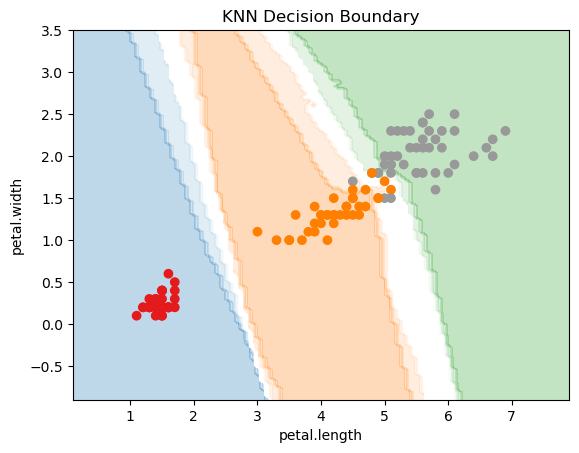

In [24]:
from sklearn.inspection import DecisionBoundaryDisplay
knn_plot = KNeighborsClassifier(n_neighbors=5).fit(x_train[['petal.length','petal.width']], y_train)
DecisionBoundaryDisplay.from_estimator(knn_plot, x_train[['petal.length','petal.width']], cmap='Pastel1', alpha=0.3)
plt.scatter(x_train['petal.length'], x_train['petal.width'], c=y_train.astype('category').cat.codes, cmap='Set1')
plt.title("KNN Decision Boundary")
plt.show()

In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
log_reg = LogisticRegression(max_iter=200)
log_reg.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [28]:
print("Training Data")

print("\nPrediction")
lpred = log_reg.predict(x_train)
print(lpred)

print("\nConfusion Matrix Training")
cm = confusion_matrix(y_train, lpred)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_train, lpred)
print(acc)

print("\nPrecision")
precision = precision_score(y_train, lpred, average='weighted')
print(precision)

print("\nRecall")
recall = recall_score(y_train, lpred, average='weighted')
print(recall)

print("\nf1")
f1 = f1_score(y_train, lpred, average='weighted')
print(f1)

Training Data

Prediction
[2 1 0 2 2 1 0 2 1 1 2 0 2 0 0 1 2 2 2 2 1 2 1 1 2 2 1 2 1 2 1 0 2 1 1 1 1
 2 0 0 2 1 0 0 1 0 2 1 0 1 2 1 0 2 2 2 2 0 0 2 2 0 2 0 2 2 0 0 2 0 0 0 1 2
 2 0 0 0 1 1 0 0 1 0 2 1 2 1 0 2 0 2 0 0 2 0 2 1 1 1 2 2 1 2 0 1 2 2 0 1 1
 2 1 0 0 0 2 1 2 0]

Confusion Matrix Training
[[39  0  0]
 [ 0 34  3]
 [ 0  1 43]]

Accuracy Score
0.9666666666666667

Precision
0.9672774327122153

Recall
0.9666666666666667

f1
0.966574074074074


In [29]:
print("Testing Data")

print("\nPrediction")
lpred = log_reg.predict(x_test)
print(lpred)

print("\nConfusion Matrix Testing")
cm = confusion_matrix(y_test, lpred)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_test, lpred)
print(acc)

print("\nPrecision")
precision = precision_score(y_test, lpred, average='weighted')
print(precision)

print("\nRecall")
recall = recall_score(y_test, lpred, average='weighted')
print(recall)

print("\nf1")
f1 = f1_score(y_test, lpred, average='weighted')
print(f1)

Testing Data

Prediction
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0]

Confusion Matrix Testing
[[11  0  0]
 [ 0 13  0]
 [ 0  0  6]]

Accuracy Score
1.0

Precision
1.0

Recall
1.0

f1
1.0


In [31]:
## print("Enter the flower details")
slength = float(input("sepal length :"))
swidth = float(input("sepal width :"))
plength = float(input("petal length"))
pwidth = float(input("petal width"))

x = data[
    ["sepal.length",
     "sepal.width",
     "petal.length",
     "petal.width"
    ]]
y = data["variety"]

user_input = [[slength, swidth, plength, pwidth]]

lpred = log_reg.predict(user_input)
variety = ["Setosa", "Versicolor", "Virginica"]

print("Predicted variety:", lpred[0], f"({variety[lpred[0]]})")

sepal length : 5.4
sepal width : 6.7
petal length 3.2
petal width 4.0


Predicted variety: 0 (Setosa)


F:\setup\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


F:\setup\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:226: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case when the response method is 'decision_function' or 'predict_proba'.
  warnings.warn(


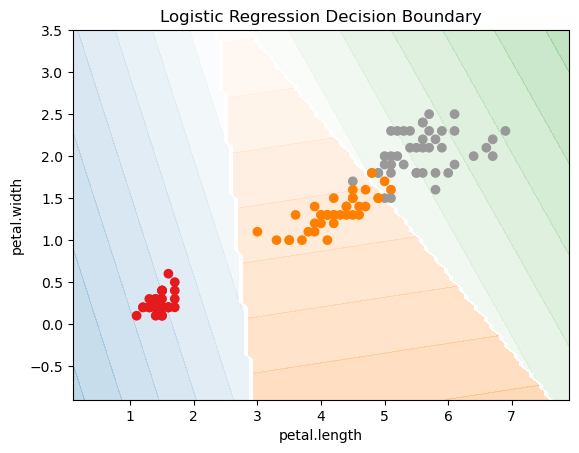

In [32]:
lr_plot = LogisticRegression(max_iter=200).fit(x_train[['petal.length','petal.width']], y_train)
DecisionBoundaryDisplay.from_estimator(lr_plot, x_train[['petal.length','petal.width']], cmap='Pastel1', alpha=0.3)
plt.scatter(x_train['petal.length'], x_train['petal.width'], c=y_train.astype('category').cat.codes, cmap='Set1')
plt.title("Logistic Regression Decision Boundary")
plt.show()